In [1]:

import torch

x = torch.tensor(2.0)
y = torch.tensor(2.0)

w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)

z = w * x + b
a = torch.relu(z)
loss = 0.5 * (a - y) ** 2

loss.backward()

print("Prediction:", a.item())
print("Loss:", loss.item())
print("Weight gradient:", w.grad.item())
print("Bias gradient:", b.grad.item())


Prediction: 1.100000023841858
Loss: 0.4049999713897705
Weight gradient: -1.7999999523162842
Bias gradient: -0.8999999761581421


In [2]:

import torch

x = torch.tensor(2.0)
y = torch.tensor(2.0)

w1 = torch.tensor(0.5, requires_grad=True)
b1 = torch.tensor(0.1, requires_grad=True)
w2 = torch.tensor(0.8, requires_grad=True)
b2 = torch.tensor(0.2, requires_grad=True)

z1 = w1 * x + b1
h = torch.relu(z1)
prediction = w2 * h + b2

loss = 0.5 * (prediction - y) ** 2
loss.backward()

print("Prediction:", prediction.item())
print("Loss:", loss.item())
print("w1 gradient:", w1.grad.item())
print("b1 gradient:", b1.grad.item())
print("w2 gradient:", w2.grad.item())
print("b2 gradient:", b2.grad.item())


Prediction: 1.0800000429153442
Loss: 0.42319995164871216
w1 gradient: -1.472000002861023
b1 gradient: -0.7360000014305115
w2 gradient: -1.0119999647140503
b2 gradient: -0.9199999570846558


**Handwritten Digit Recognition**

In [3]:

import sys
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
CUDA available: False


In [4]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 108MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.27MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 26.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.47MB/s]


Training samples: 55000
Validation samples: 5000
Test samples: 10000


Image shape: torch.Size([1, 28, 28])
Pixel minimum: 0.0
Pixel maximum: 1.0
Label: 5


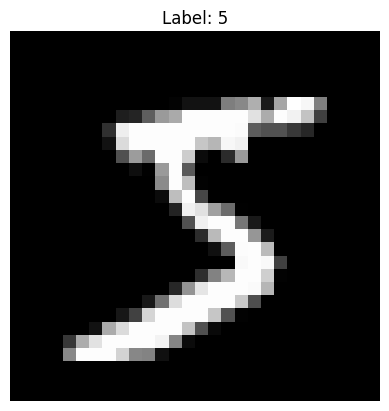

In [5]:

image, label = full_train_dataset[0]

print("Image shape:", image.shape)
print("Pixel minimum:", image.min().item())
print("Pixel maximum:", image.max().item())
print("Label:", label)

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()


In [6]:

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [7]:

import torch.nn as nn

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DigitClassifier().to(device)

print(model)
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


DigitClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Device: cpu
Trainable parameters: 101770


In [8]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [9]:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


In [10]:

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


In [11]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


Epoch 01/10 | Train Loss: 0.3545 | Train Acc: 0.9073 | Val Loss: 0.2071 | Val Acc: 0.9416
Epoch 02/10 | Train Loss: 0.1618 | Train Acc: 0.9533 | Val Loss: 0.1556 | Val Acc: 0.9536
Epoch 03/10 | Train Loss: 0.1150 | Train Acc: 0.9668 | Val Loss: 0.1326 | Val Acc: 0.9628
Epoch 04/10 | Train Loss: 0.0868 | Train Acc: 0.9753 | Val Loss: 0.1164 | Val Acc: 0.9640
Epoch 05/10 | Train Loss: 0.0690 | Train Acc: 0.9797 | Val Loss: 0.1006 | Val Acc: 0.9696
Epoch 06/10 | Train Loss: 0.0554 | Train Acc: 0.9838 | Val Loss: 0.0989 | Val Acc: 0.9716
Epoch 07/10 | Train Loss: 0.0449 | Train Acc: 0.9868 | Val Loss: 0.0963 | Val Acc: 0.9702
Epoch 08/10 | Train Loss: 0.0374 | Train Acc: 0.9887 | Val Loss: 0.0905 | Val Acc: 0.9720
Epoch 09/10 | Train Loss: 0.0306 | Train Acc: 0.9914 | Val Loss: 0.0967 | Val Acc: 0.9728
Epoch 10/10 | Train Loss: 0.0257 | Train Acc: 0.9925 | Val Loss: 0.0928 | Val Acc: 0.9734


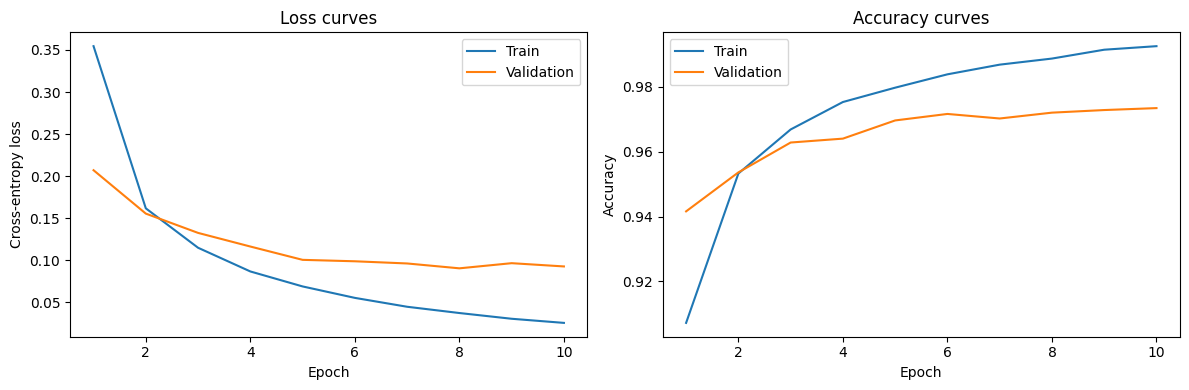

In [12]:

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train")
plt.plot(epochs_range, history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Loss curves")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_accuracy"], label="Train")
plt.plot(epochs_range, history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy curves")
plt.legend()

plt.tight_layout()
plt.show()


In [13]:
test_loss, test_acc = evaluate(
    model, test_loader, criterion, device
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f}%")

Test loss: 0.0747
Test accuracy: 97.92%


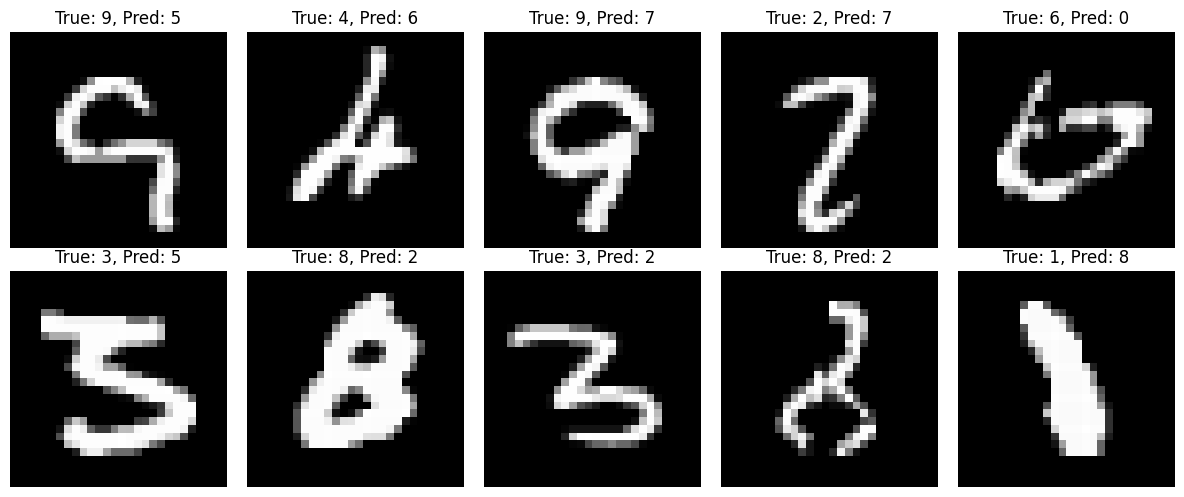

In [14]:

@torch.no_grad()
def collect_mistakes(model, loader, device):
    model.eval()
    mistakes = []

    for images, labels in loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        wrong_indices = (predictions != labels).nonzero().flatten()

        for idx in wrong_indices.tolist():
            mistakes.append(
                (images[idx].squeeze(0), labels[idx].item(),
                 predictions[idx].item())
            )

    return mistakes


mistakes = collect_mistakes(model, test_loader, device)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, (image, true_label, pred_label) in zip(axes.flat, mistakes[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: {true_label}, Pred: {pred_label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


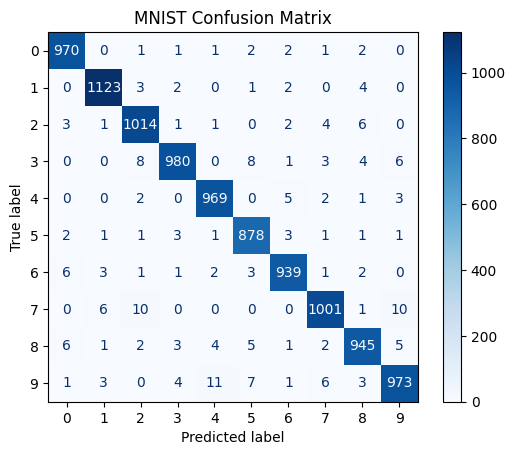

In [15]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

display.plot(cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.show()


In [16]:

import copy

torch.manual_seed(42)
initial_model = DigitClassifier()

experiments = [
    ("SGD", 0.01, "sgd"),
    ("Momentum", 0.01, "momentum"),
    ("RMSProp", 0.001, "rmsprop"),
    ("Adam", 0.001, "adam"),
    ("AdamW", 0.001, "adamw"),
]

results = {}

for name, lr, optimizer_name in experiments:
    experiment_model = copy.deepcopy(initial_model).to(device)

    if optimizer_name == "sgd":
        experiment_optimizer = torch.optim.SGD(
            experiment_model.parameters(), lr=lr
        )
    elif optimizer_name == "momentum":
        experiment_optimizer = torch.optim.SGD(
            experiment_model.parameters(),
            lr=lr,
            momentum=0.9
        )
    elif optimizer_name == "rmsprop":
        experiment_optimizer = torch.optim.RMSprop(
            experiment_model.parameters(), lr=lr
        )
    elif optimizer_name == "adam":
        experiment_optimizer = torch.optim.Adam(
            experiment_model.parameters(), lr=lr
        )
    else:
        experiment_optimizer = torch.optim.AdamW(
            experiment_model.parameters(), lr=lr
        )

    run_history = []

    for epoch in range(5):
        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_loader,
            criterion,
            experiment_optimizer,
            device
        )

        val_loss, val_acc = evaluate(
            experiment_model,
            val_loader,
            criterion,
            device
        )

        run_history.append({
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

    results[name] = run_history

    print(
        name,
        "Final validation accuracy:",
        f"{run_history[-1]['val_accuracy'] * 100:.2f}%"
    )


SGD Final validation accuracy: 90.22%
Momentum Final validation accuracy: 96.18%
RMSProp Final validation accuracy: 96.62%
Adam Final validation accuracy: 97.32%
AdamW Final validation accuracy: 97.06%
